# **Download Datasets**



In [ ]:
# Download necessary packages
!pip install gdown
!pip install pandas

# Download Haiti Dataset
!gdown 1lyemu9dz6L1YS-MTNU25KWSN4X0AydXa # Train
!gdown 1eZtMBEO3kkpd3WzkPeWR2-6DK2uygLNR # Test

# Download Sandy Dataset
!gdown 14AG0JK9t6iYR4nvWhxuU6QyBhoOYD-_5 # Train
!gdown 1gpKC6Ks0nQDkZ8TOBjKZeblhIJiG520e # Test

Downloading...
From: https://drive.google.com/uc?id=1lyemu9dz6L1YS-MTNU25KWSN4X0AydXa
To: /content/haiti_train.csv
100% 172k/172k [00:00<00:00, 89.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1eZtMBEO3kkpd3WzkPeWR2-6DK2uygLNR
To: /content/haiti_test.csv
100% 43.9k/43.9k [00:00<00:00, 50.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=14AG0JK9t6iYR4nvWhxuU6QyBhoOYD-_5
To: /content/sandy_train.csv
100% 155k/155k [00:00<00:00, 92.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1gpKC6Ks0nQDkZ8TOBjKZeblhIJiG520e
To: /content/sandy_test.csv
100% 40.2k/40.2k [00:00<00:00, 49.5MB/s]


# **Load Datasets**





In [ ]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import class_weight
# Load the datasets
haiti_train_df = pd.read_csv('haiti_train.csv')
haiti_test_df = pd.read_csv('haiti_test.csv')
sandy_train_df = pd.read_csv('sandy_train.csv')
sandy_test_df = pd.read_csv('sandy_test.csv')

# **Data Labeling and Categorization**

In [ ]:
# Convert labels to numeric values
label_mapping = {'Food': 0, 'Water': 1, 'Energy': 2, 'Medical': 3, 'NaN': 4}

haiti_train_df['Label'] = haiti_train_df['Label'].map(label_mapping)
haiti_test_df['Label'] = haiti_test_df['Label'].map(label_mapping)
sandy_train_df['Label'] = sandy_train_df['Label'].map(label_mapping)
sandy_test_df['Label'] = sandy_test_df['Label'].map(label_mapping)

# **Data Cleaning**

In [ ]:
# Handle missing values by dropping rows with missing data
haiti_train_df = haiti_train_df.dropna()
haiti_test_df = haiti_test_df.dropna()
sandy_train_df = sandy_train_df.dropna()
sandy_test_df = sandy_test_df.dropna()

# Remove duplicate entries
haiti_train_df = haiti_train_df.drop_duplicates()
haiti_test_df = haiti_test_df.drop_duplicates()
sandy_train_df = sandy_train_df.drop_duplicates()
sandy_test_df = sandy_test_df.drop_duplicates()

# **Text Preprocessing**

In [ ]:
# Download NLTK data
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    # Lowercase the text
    text = text.lower()
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Tokenization
    tokens = text.split()
    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]
    # Stemming
    tokens = [stemmer.stem(word) for word in tokens]
    # Join tokens back to string
    return ' '.join(tokens)

# Apply preprocessing
haiti_train_df['processed_text'] = haiti_train_df['Text'].apply(preprocess_text)
haiti_test_df['processed_text'] = haiti_test_df['Text'].apply(preprocess_text)
sandy_train_df['processed_text'] = sandy_train_df['Text'].apply(preprocess_text)
sandy_test_df['processed_text'] = sandy_test_df['Text'].apply(preprocess_text)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# EDA Visualization

<ipython-input-31-ac24cbf344af>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=haiti_train_preprocessed_df, x='Label', palette='viridis')
<ipython-input-31-ac24cbf344af>:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=sandy_train_preprocessed_df, x='Label', palette='viridis')


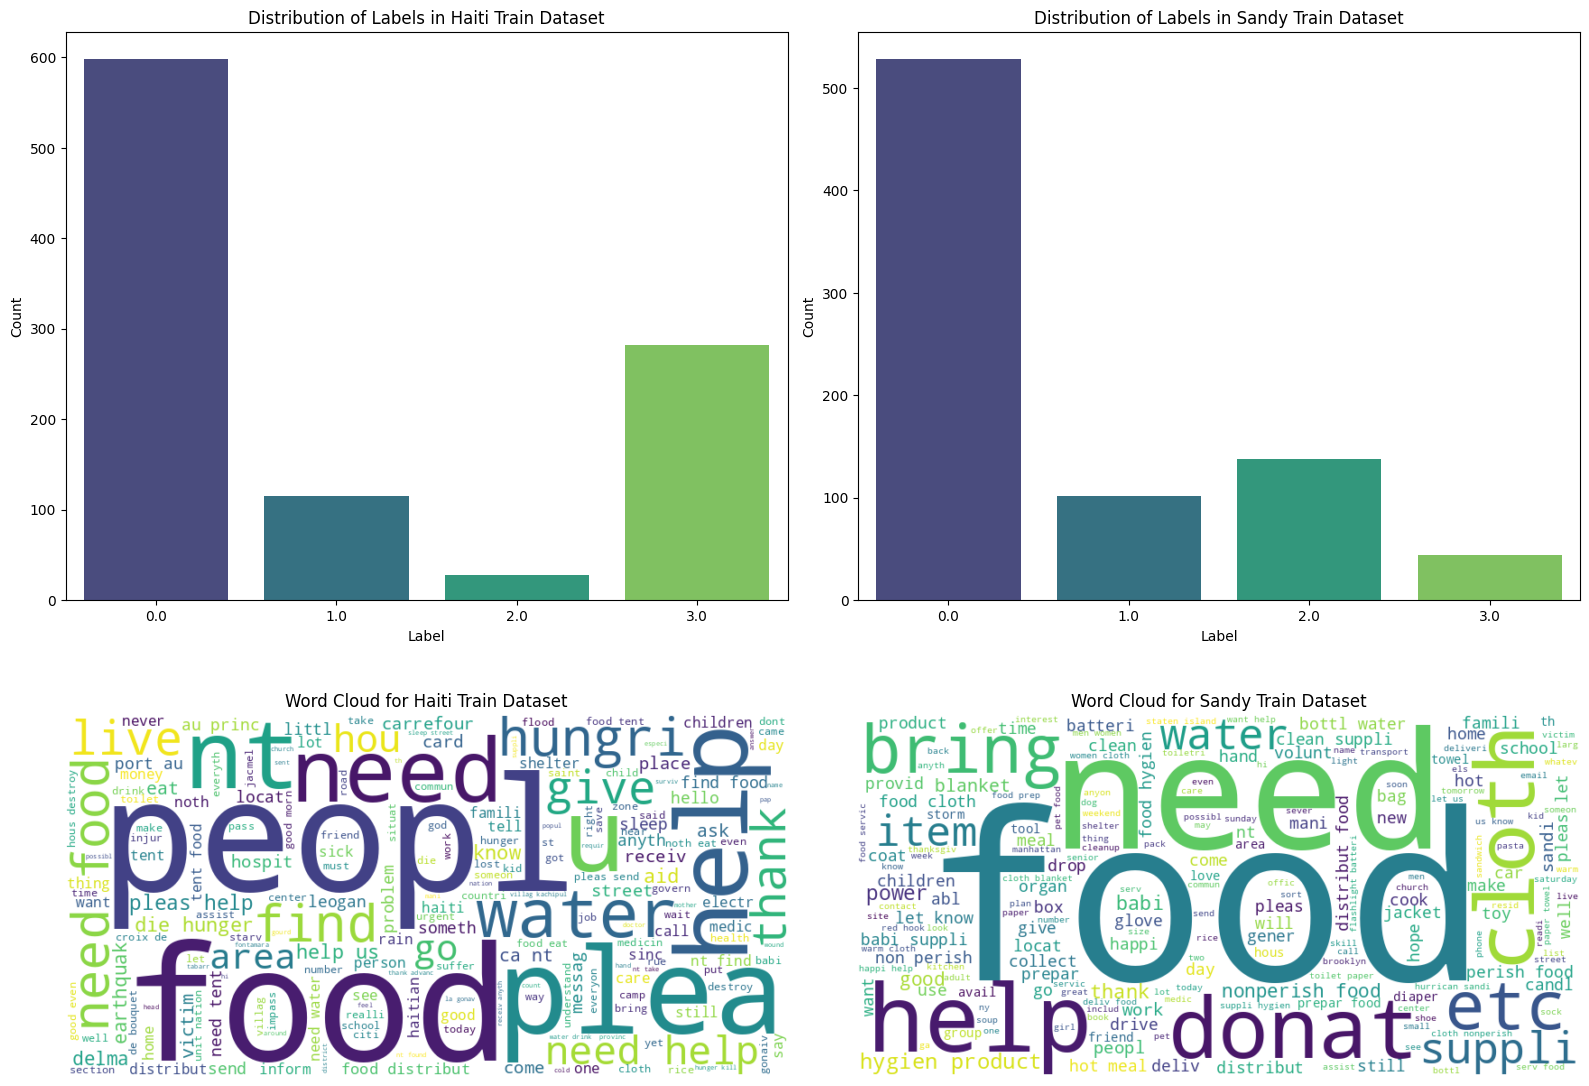

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the preprocessed datasets
haiti_train_preprocessed_df = pd.read_csv('haiti_train_preprocessed.csv')
sandy_train_preprocessed_df = pd.read_csv('sandy_train_preprocessed.csv')

# Set up the visualizations
plt.figure(figsize=(16, 12))

# Plot 1: Distribution of Labels in Haiti Train Dataset
plt.subplot(2, 2, 1)
sns.countplot(data=haiti_train_preprocessed_df, x='Label', palette='viridis')
plt.title('Distribution of Labels in Haiti Train Dataset')
plt.xlabel('Label')
plt.ylabel('Count')

# Plot 2: Distribution of Labels in Sandy Train Dataset
plt.subplot(2, 2, 2)
sns.countplot(data=sandy_train_preprocessed_df, x='Label', palette='viridis')
plt.title('Distribution of Labels in Sandy Train Dataset')
plt.xlabel('Label')
plt.ylabel('Count')

# Plot 3: Word Cloud for Haiti Train Dataset
from wordcloud import WordCloud

haiti_text = ' '.join(haiti_train_preprocessed_df['processed_text'].tolist())
wordcloud_haiti = WordCloud(width=800, height=400, background_color='white').generate(haiti_text)

plt.subplot(2, 2, 3)
plt.imshow(wordcloud_haiti, interpolation='bilinear')
plt.title('Word Cloud for Haiti Train Dataset')
plt.axis('off')

# Plot 4: Word Cloud for Sandy Train Dataset
sandy_text = ' '.join(sandy_train_preprocessed_df['processed_text'].tolist())
wordcloud_sandy = WordCloud(width=800, height=400, background_color='white').generate(sandy_text)

plt.subplot(2, 2, 4)
plt.imshow(wordcloud_sandy, interpolation='bilinear')
plt.title('Word Cloud for Sandy Train Dataset')
plt.axis('off')

# Display the visualizations
plt.tight_layout()
plt.show()

# Feature **Engineering**

In [ ]:
# Create and fit vectorizer on training data
haiti_vectorizer = TfidfVectorizer(max_features=1500)
sandy_vectorizer = TfidfVectorizer(max_features=1500)

haiti_train_tfidf = haiti_vectorizer.fit_transform(haiti_train_df['processed_text'])
sandy_train_tfidf = sandy_vectorizer.fit_transform(sandy_train_df['processed_text'])

# Transform test data using the fitted vectorizer
haiti_test_tfidf = haiti_vectorizer.transform(haiti_test_df['processed_text'])
sandy_test_tfidf = sandy_vectorizer.transform(sandy_test_df['processed_text'])

# Feature Selection (Optional, if needed)

In [ ]:
# Feature selection using PCA on training data
haiti_pca = PCA(n_components=100)
sandy_pca = PCA(n_components=100)

haiti_train_tfidf_pca = haiti_pca.fit_transform(haiti_train_tfidf.toarray())
sandy_train_tfidf_pca = sandy_pca.fit_transform(sandy_train_tfidf.toarray())

# Transform test data using the fitted PCA
haiti_test_tfidf_pca = haiti_pca.transform(haiti_test_tfidf.toarray())
sandy_test_tfidf_pca = sandy_pca.transform(sandy_test_tfidf.toarray())

# Logistic Regression Model - Param

In [ ]:
# Logistic Regression model
clf_lr = LogisticRegression(max_iter=1000)
clf_lr_haiti = clf_lr.fit(haiti_train_tfidf_pca, haiti_train_df['Label'])
clf_lr_sandy = clf_lr.fit(sandy_train_tfidf_pca, sandy_train_df['Label'])

haiti_test_predictions_lr = clf_lr_haiti.predict(haiti_test_tfidf_pca)
sandy_test_predictions_lr = clf_lr_sandy.predict(sandy_test_tfidf_pca)

haiti_test_accuracy_lr = accuracy_score(haiti_test_df['Label'], haiti_test_predictions_lr)
sandy_test_accuracy_lr = accuracy_score(sandy_test_df['Label'], sandy_test_predictions_lr)

print(f'Haiti Logistic Regression Test Accuracy: {haiti_test_accuracy_lr}')
print(f'Sandy Logistic Regression Test Accuracy: {sandy_test_accuracy_lr}')
print('\nHaiti Logistic Regression Classification Report:\n', classification_report(haiti_test_df['Label'], haiti_test_predictions_lr))
print('\nSandy Logistic Regression Classification Report:\n', classification_report(sandy_test_df['Label'], sandy_test_predictions_lr))

# Confusion Matrix for Haiti Logistic Regression Model
cm_haiti_lr = confusion_matrix(haiti_test_df['Label'], haiti_test_predictions_lr)

# Confusion Matrix for Sandy Logistic Regression Model
cm_sandy_lr = confusion_matrix(sandy_test_df['Label'], sandy_test_predictions_lr)

# Define class names
class_names = ['Food', 'Water', 'Energy', 'Medical', 'N/A']

# Plot Confusion Matrices
plt.figure(figsize=(16, 12))

# Haiti Logistic Regression Confusion Matrix
plt.subplot(2, 2, 1)
sns.heatmap(cm_haiti_lr, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Haiti Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Sandy Logistic Regression Confusion Matrix
plt.subplot(2, 2, 2)
sns.heatmap(cm_sandy_lr, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Sandy Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

ValueError: Unknown label type: 'unknown'

# KNN Model- Nathaniel

In [ ]:
#KNN
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plot

knn_haiti = KNeighborsClassifier(n_neighbors=3)
knn_haiti.fit(haiti_train_tfidf_df, haiti_train_df['Label'])

haiti_pred = knn_haiti.predict(haiti_test_tfidf_df)
haiti_accuracy = accuracy_score(haiti_test_df['Label'], haiti_pred)

print(f'Haiti Test Dataset Accuracy: {haiti_accuracy}')


haiti_pred = knn_haiti.predict(haiti_train_tfidf_df)
haiti_accuracy = accuracy_score(haiti_train_df['Label'], haiti_pred)

print(f'Haiti Train Dataset Accuracy: {haiti_accuracy}')

### haiti analog

knn_sandy = KNeighborsClassifier(n_neighbors=3)
knn_sandy.fit(sandy_train_tfidf_df, sandy_train_df['Label'])

sandy_pred = knn_sandy.predict(sandy_test_tfidf_df)
sandy_accuracy = accuracy_score(sandy_test_df['Label'], sandy_pred)

print(f'Sandy Test Dataset Accuracy: {sandy_accuracy}')


sandy_pred = knn_sandy.predict(sandy_train_tfidf_df)
sandy_accuracy = accuracy_score(sandy_train_df['Label'], sandy_pred)

print(f'Sandy Train Dataset Accuracy: {sandy_accuracy}')


NameError: name 'haiti_train_tfidf_df' is not defined

#Decision Tree Model-Abdullah

In [ ]:
clf_dt = DecisionTreeClassifier(max_depth=3)
clf_dt_haiti = clf_dt.fit(haiti_train_tfidf_pca, haiti_train_df['Label'])
clf_dt_sandy = clf_dt.fit(sandy_train_tfidf_pca, sandy_train_df['Label'])

haiti_test_predictions_dt = clf_dt_haiti.predict(haiti_test_tfidf_pca)
sandy_test_predictions_dt = clf_dt_sandy.predict(sandy_test_tfidf_pca)

haiti_test_accuracy_dt = accuracy_score(haiti_test_df['Label'], haiti_test_predictions_dt)
sandy_test_accuracy_dt = accuracy_score(sandy_test_df['Label'], sandy_test_predictions_dt)

print(f'Haiti Decision Tree Test Accuracy: {haiti_test_accuracy_dt}')
print(f'Sandy Decision Tree Test Accuracy: {sandy_test_accuracy_dt}')
print('\nHaiti Decision Tree Classification Report:\n', classification_report(haiti_test_df['Label'], haiti_test_predictions_dt))
print('\nSandy Decision Tree Classification Report:\n', classification_report(sandy_test_df['Label'], sandy_test_predictions_dt))

Haiti Decision Tree Test Accuracy: 0.509090909090909
Sandy Decision Tree Test Accuracy: 0.7722772277227723

Haiti Decision Tree Classification Report:
               precision    recall  f1-score   support

         0.0       0.59      0.84      0.69       165
         1.0       0.00      0.00      0.00        25
         2.0       0.08      0.25      0.12         4
         3.0       0.00      0.00      0.00        81

    accuracy                           0.51       275
   macro avg       0.17      0.27      0.20       275
weighted avg       0.36      0.51      0.42       275


Sandy Decision Tree Classification Report:
               precision    recall  f1-score   support

         0.0       0.78      0.95      0.86       129
         1.0       0.75      0.60      0.67        20
         2.0       0.70      0.47      0.57        40
         3.0       1.00      0.23      0.38        13

    accuracy                           0.77       202
   macro avg       0.81      0.56      0.6

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


Haiti Logistic Regression Test Accuracy: 0.195
Sandy Logistic Regression Test Accuracy: 0.7722419928825622

Haiti Logistic Regression Classification Report:
               precision    recall  f1-score   support

         0.0       0.27      0.39      0.32       165
         1.0       0.00      0.00      0.00        25
         2.0       0.04      0.25      0.06         4
         3.0       0.00      0.00      0.00        81
         4.0       0.12      0.10      0.11       125

    accuracy                           0.20       400
   macro avg       0.09      0.15      0.10       400
weighted avg       0.15      0.20      0.17       400


Sandy Logistic Regression Classification Report:
               precision    recall  f1-score   support

         0.0       0.79      0.93      0.86       129
         1.0       0.78      0.70      0.74        20
         2.0       0.76      0.40      0.52        40
         3.0       1.00      0.08      0.14        13
         4.0       0.73      0.

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


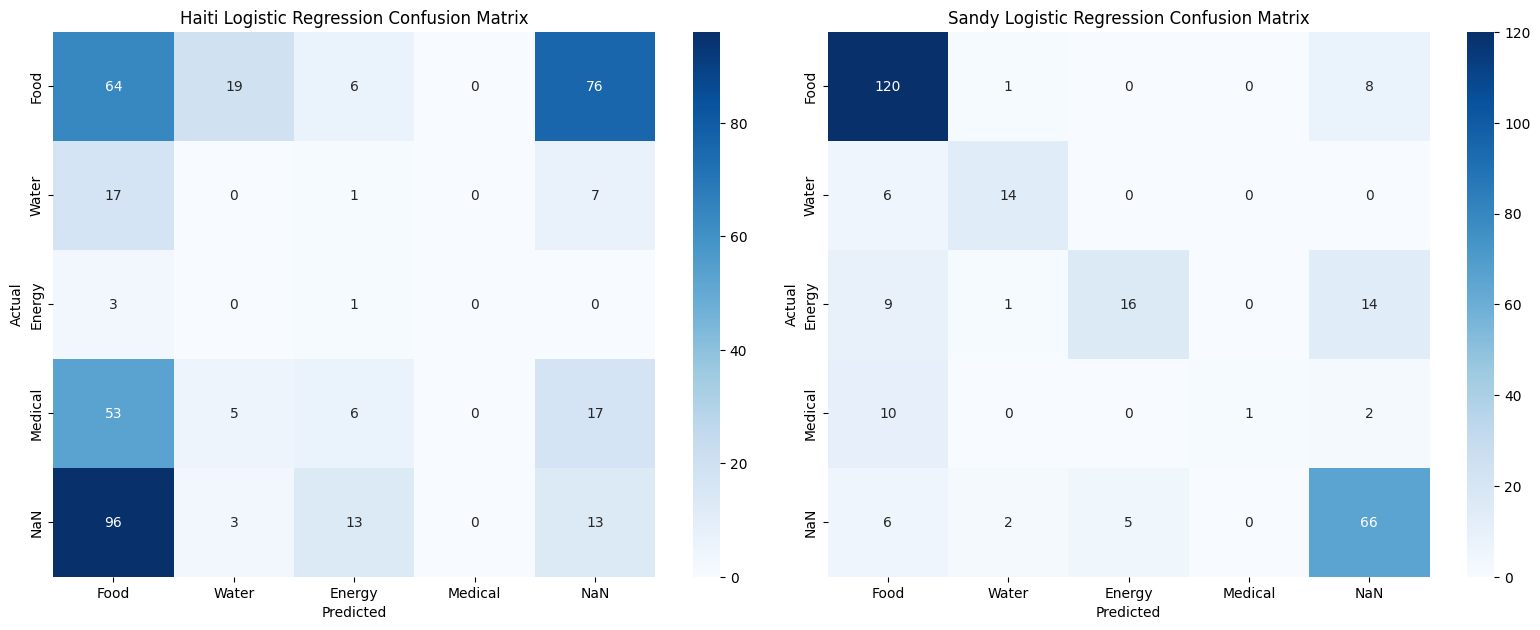

Haiti Decision Tree Test Accuracy: 0.22
Sandy Decision Tree Test Accuracy: 0.708185053380783

Haiti Decision Tree Classification Report:
               precision    recall  f1-score   support

         0.0       0.29      0.51      0.37       165
         1.0       0.07      0.12      0.08        25
         2.0       0.00      0.00      0.00         4
         3.0       0.00      0.00      0.00        81
         4.0       0.02      0.01      0.01       125

    accuracy                           0.22       400
   macro avg       0.08      0.13      0.09       400
weighted avg       0.13      0.22      0.16       400


Sandy Decision Tree Classification Report:
               precision    recall  f1-score   support

         0.0       0.71      0.94      0.81       129
         1.0       0.74      0.70      0.72        20
         2.0       0.64      0.35      0.45        40
         3.0       0.00      0.00      0.00        13
         4.0       0.71      0.63      0.67        79

  

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classif

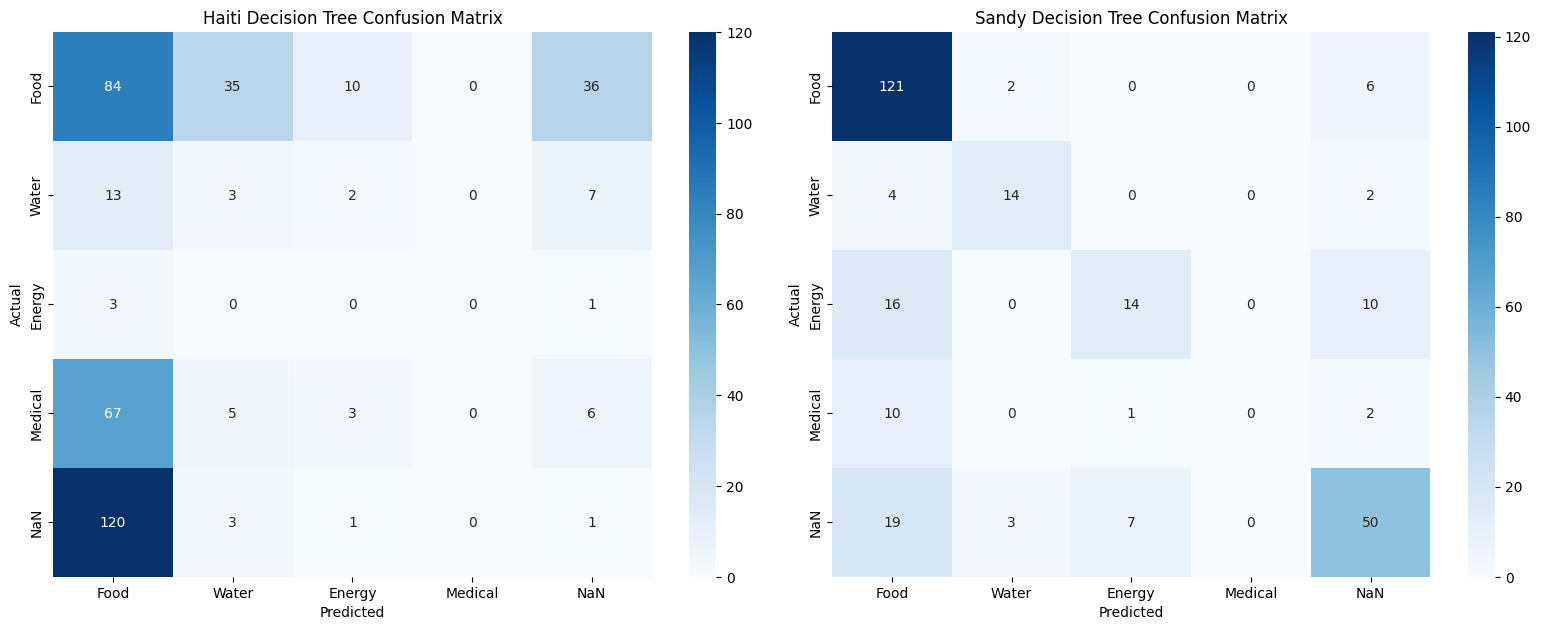

In [ ]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
haiti_train_df = pd.read_csv('haiti_train.csv')
haiti_test_df = pd.read_csv('haiti_test.csv')
sandy_train_df = pd.read_csv('sandy_train.csv')
sandy_test_df = pd.read_csv('sandy_test.csv')

# Convert labels to numeric values
label_mapping = {'Food': 0, 'Water': 1, 'Energy': 2, 'Medical': 3, 'NaN': 4}

haiti_train_df['Label'] = haiti_train_df['Label'].map(label_mapping)
haiti_test_df['Label'] = haiti_test_df['Label'].map(label_mapping)
sandy_train_df['Label'] = sandy_train_df['Label'].map(label_mapping)
sandy_test_df['Label'] = sandy_test_df['Label'].map(label_mapping)

# Handle missing values by filling NaN values in the label column with 'NaN' class
haiti_train_df['Label'] = haiti_train_df['Label'].fillna(label_mapping['NaN'])
haiti_test_df['Label'] = haiti_test_df['Label'].fillna(label_mapping['NaN'])
sandy_train_df['Label'] = sandy_train_df['Label'].fillna(label_mapping['NaN'])
sandy_test_df['Label'] = sandy_test_df['Label'].fillna(label_mapping['NaN'])

# Remove duplicate entries
haiti_train_df = haiti_train_df.drop_duplicates()
haiti_test_df = haiti_test_df.drop_duplicates()
sandy_train_df = sandy_train_df.drop_duplicates()
sandy_test_df = sandy_test_df.drop_duplicates()

# Download NLTK data
nltk.download('stopwords')
nltk.download('punkt')

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    # Lowercase the text
    text = text.lower()
    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Tokenization
    tokens = text.split()
    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]
    # Stemming
    tokens = [stemmer.stem(word) for word in tokens]
    # Join tokens back to string
    return ' '.join(tokens)

# Apply preprocessing
haiti_train_df['processed_text'] = haiti_train_df['Text'].apply(preprocess_text)
haiti_test_df['processed_text'] = haiti_test_df['Text'].apply(preprocess_text)
sandy_train_df['processed_text'] = sandy_train_df['Text'].apply(preprocess_text)
sandy_test_df['processed_text'] = sandy_test_df['Text'].apply(preprocess_text)

# Create and fit vectorizer on training data
haiti_vectorizer = TfidfVectorizer(max_features=1000)
sandy_vectorizer = TfidfVectorizer(max_features=1000)

haiti_train_tfidf = haiti_vectorizer.fit_transform(haiti_train_df['processed_text'])
sandy_train_tfidf = sandy_vectorizer.fit_transform(sandy_train_df['processed_text'])

# Transform test data using the fitted vectorizer
haiti_test_tfidf = haiti_vectorizer.transform(haiti_test_df['processed_text'])
sandy_test_tfidf = sandy_vectorizer.transform(sandy_test_df['processed_text'])

# Feature selection using PCA on training data
haiti_pca = PCA(n_components=100)
sandy_pca = PCA(n_components=100)

haiti_train_tfidf_pca = haiti_pca.fit_transform(haiti_train_tfidf.toarray())
sandy_train_tfidf_pca = sandy_pca.fit_transform(sandy_train_tfidf.toarray())

# Transform test data using the fitted PCA
haiti_test_tfidf_pca = haiti_pca.transform(haiti_test_tfidf.toarray())
sandy_test_tfidf_pca = sandy_pca.transform(sandy_test_tfidf.toarray())

# Logistic Regression model
clf_lr = LogisticRegression(max_iter=1000)
clf_lr_haiti = clf_lr.fit(haiti_train_tfidf_pca, haiti_train_df['Label'])
clf_lr_sandy = clf_lr.fit(sandy_train_tfidf_pca, sandy_train_df['Label'])

haiti_test_predictions_lr = clf_lr_haiti.predict(haiti_test_tfidf_pca)
sandy_test_predictions_lr = clf_lr_sandy.predict(sandy_test_tfidf_pca)

haiti_test_accuracy_lr = accuracy_score(haiti_test_df['Label'], haiti_test_predictions_lr)
sandy_test_accuracy_lr = accuracy_score(sandy_test_df['Label'], sandy_test_predictions_lr)

print(f'Haiti Logistic Regression Test Accuracy: {haiti_test_accuracy_lr}')
print(f'Sandy Logistic Regression Test Accuracy: {sandy_test_accuracy_lr}')
print('\nHaiti Logistic Regression Classification Report:\n', classification_report(haiti_test_df['Label'], haiti_test_predictions_lr))
print('\nSandy Logistic Regression Classification Report:\n', classification_report(sandy_test_df['Label'], sandy_test_predictions_lr))

# Confusion Matrix for Haiti Logistic Regression Model
cm_haiti_lr = confusion_matrix(haiti_test_df['Label'], haiti_test_predictions_lr)
# Confusion Matrix for Sandy Logistic Regression Model
cm_sandy_lr = confusion_matrix(sandy_test_df['Label'], sandy_test_predictions_lr)

# Define class names
class_names = ['Food', 'Water', 'Energy', 'Medical', 'NaN']

# Plot Confusion Matrices
plt.figure(figsize=(16, 12))

# Haiti Logistic Regression Confusion Matrix
plt.subplot(2, 2, 1)
sns.heatmap(cm_haiti_lr, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Haiti Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Sandy Logistic Regression Confusion Matrix
plt.subplot(2, 2, 2)
sns.heatmap(cm_sandy_lr, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Sandy Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

# Decision Tree model
clf_dt = DecisionTreeClassifier(max_depth=3)
clf_dt_haiti = clf_dt.fit(haiti_train_tfidf_pca, haiti_train_df['Label'])
clf_dt_sandy = clf_dt.fit(sandy_train_tfidf_pca, sandy_train_df['Label'])

haiti_test_predictions_dt = clf_dt_haiti.predict(haiti_test_tfidf_pca)
sandy_test_predictions_dt = clf_dt_sandy.predict(sandy_test_tfidf_pca)

haiti_test_accuracy_dt = accuracy_score(haiti_test_df['Label'], haiti_test_predictions_dt)
sandy_test_accuracy_dt = accuracy_score(sandy_test_df['Label'], sandy_test_predictions_dt)

print(f'Haiti Decision Tree Test Accuracy: {haiti_test_accuracy_dt}')
print(f'Sandy Decision Tree Test Accuracy: {sandy_test_accuracy_dt}')
print('\nHaiti Decision Tree Classification Report:\n', classification_report(haiti_test_df['Label'], haiti_test_predictions_dt))
print('\nSandy Decision Tree Classification Report:\n', classification_report(sandy_test_df['Label'], sandy_test_predictions_dt))

# Confusion Matrix for Haiti Decision Tree Model
cm_haiti_dt = confusion_matrix(haiti_test_df['Label'], haiti_test_predictions_dt)
# Confusion Matrix for Sandy Decision Tree Model
cm_sandy_dt = confusion_matrix(sandy_test_df['Label'], sandy_test_predictions_dt)

# Plot Confusion Matrices for Decision Tree
plt.figure(figsize=(16, 12))

# Haiti Decision Tree Confusion Matrix
plt.subplot(2, 2, 3)
sns.heatmap(cm_haiti_dt, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Haiti Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Sandy Decision Tree Confusion Matrix
plt.subplot(2, 2, 4)
sns.heatmap(cm_sandy_dt, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Sandy Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

In [ ]:

# Check the unique values in the 'Label' column before and after mapping
print(haiti_train_df['Label'].unique())
print(haiti_test_df['Label'].unique())
print(sandy_train_df['Label'].unique())
print(sandy_test_df['Label'].unique())


[nan]
[nan]
[nan]
[nan]
